In [2]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/data

import os
try:
    print([f for f in os.listdir("/content/drive/MyDrive") if "plant" in f.lower() or f.lower().endswith(".zip")])
except Exception as e:
    print("Error reading Drive directory:", e)
    !mkdir -p /content/data
!unzip -q "/content/drive/MyDrive/archive.zip" -d /content/data

Mounted at /content/drive
['archive.zip', 'plant_manifest.csv']


In [3]:
!unzip -o -q "/content/drive/MyDrive/archive.zip" -d /content/data

In [4]:
!ls /content/data

'plantvillage dataset'


In [9]:
wanted = [
    "Tomato___healthy", "Tomato___Early_blight", "Tomato___Late_blight",
    "Potato___healthy", "Potato___Early_blight", "Potato___Late_blight",
    "Pepper,_bell___healthy", "Pepper,_bell___Bacterial_spot",
]

selected = {}
for p in folders:
    path = Path(p)
    if path.name in wanted and "color" in [part.lower() for part in path.parts]:
        selected[path.name] = path

print(len(selected), "of", len(wanted), "classes found")
print(sum(folders[str(p)] for p in selected.values()), "images total")

8 of 8 classes found
9127 images total


In [10]:
from PIL import Image
bad = []
for name, path in selected.items():
    for f in path.iterdir():
        if f.suffix.lower() in exts:
            try:
                with Image.open(f) as im:
                    im.verify()
            except Exception:
                bad.append(f)
print("corrupted:", len(bad))

corrupted: 0


In [11]:
import hashlib, collections
seen = collections.defaultdict(list)
for name, path in selected.items():
    for f in path.iterdir():
        if f.suffix.lower() in exts:
            seen[hashlib.md5(f.read_bytes()).hexdigest()].append(f)
dups = {h: fs for h, fs in seen.items() if len(fs) > 1}
print("duplicate groups:", len(dups))

duplicate groups: 14


In [12]:
for name, path in selected.items():
    files = sorted(f.name for f in path.iterdir() if f.suffix.lower() in exts)
    aug = [f for f in files if any(k in f.lower() for k in ("flip", "rot", "copy", "aug", "mirror"))]
    print(name, "| augmented-looking names:", len(aug))
    print("   samples:", files[:3])

Potato___Late_blight | augmented-looking names: 0
   samples: ['0051e5e8-d1c4-4a84-bf3a-a426cdad6285___RS_LB 4640.JPG', '00695906-210d-4a9d-822e-986a17384115___RS_LB 4026.JPG', '006cc01a-1888-4326-9b62-a65cb55a6377___RS_LB 5207.JPG']
Potato___healthy | augmented-looking names: 0
   samples: ['00fc2ee5-729f-4757-8aeb-65c3355874f2___RS_HL 1864.JPG', '03da9931-e514-4cc7-b04a-8f474a133ce5___RS_HL 1830.JPG', '04481ca2-f94c-457e-b785-1ac05800b7ec___RS_HL 1930.JPG']
Tomato___healthy | augmented-looking names: 0
   samples: ['000146ff-92a4-4db6-90ad-8fce2ae4fddd___GH_HL Leaf 259.1.JPG', '000bf685-b305-408b-91f4-37030f8e62db___GH_HL Leaf 308.1.JPG', '0031da2a-8edd-468f-a8b1-106657717a32___RS_HL 0105.JPG']
Tomato___Late_blight | augmented-looking names: 0
   samples: ['0003faa8-4b27-4c65-bf42-6d9e352ca1a5___RS_Late.B 4946.JPG', '00355ec2-f12c-4015-b8f9-94354f69ce22___RS_Late.B 5311.JPG', '005a2c1f-4e15-49e4-9e5c-61dc3ecf9708___RS_Late.B 5096.JPG']
Potato___Early_blight | augmented-looking names:

In [13]:
for h, fs in dups.items():
    print([(f.parent.name, f.name) for f in fs])

[('Tomato___healthy', '37203047-d8ba-43f7-b31e-d496c41c569c___GH_HL Leaf 389.JPG'), ('Tomato___healthy', '505465db-407b-4e0a-8110-7479dad5261c___GH_HL Leaf 389.JPG')]
[('Tomato___healthy', '1af0bfe1-4bcf-4b8b-be66-5d0953eb647e___GH_HL Leaf 482.2.JPG'), ('Tomato___healthy', 'cfd491d6-4af5-4728-8f0e-0d330a07174a___GH_HL Leaf 482.2.JPG')]
[('Tomato___healthy', '9662364c-aaba-45e3-b907-10792d60578c___GH_HL Leaf 220.JPG'), ('Tomato___healthy', 'd2ce7896-6fa4-45e6-96c5-d162da0e3e1c___GH_HL Leaf 220.JPG')]
[('Tomato___healthy', '37aad83b-7ff8-4b35-b3ed-fb8e0f54910b___GH_HL Leaf 342.1.JPG'), ('Tomato___healthy', 'e786ac89-29fe-47e3-b49e-b9a9ee7edd9d___GH_HL Leaf 342.1.JPG')]
[('Tomato___healthy', '488feb1c-4b9f-44e7-8aa6-4103a9601f5f___GH_HL Leaf 434.JPG'), ('Tomato___healthy', 'a5de43e7-fc2f-4a14-a8e6-c0f2f94c84f1___GH_HL Leaf 434.JPG')]
[('Tomato___healthy', '34c81c57-e1fa-49dd-a49d-34fe8b2385fe___GH_HL Leaf 466.1.JPG'), ('Tomato___healthy', '068e324c-faf6-40d6-8f83-578907f1cac5___GH_HL Leaf

In [14]:
stem = collections.defaultdict(list)
for name, path in selected.items():
    for f in path.iterdir():
        if f.suffix.lower() in exts:
            stem[f.name.split("___", 1)[-1].lower()].append((name, f.name))
same = {k: v for k, v in stem.items() if len(v) > 1}
print("original-name collisions:", len(same))
for k, v in list(same.items())[:5]:
    print(k, v)

original-name collisions: 14
gh_hl leaf 389.jpg [('Tomato___healthy', '37203047-d8ba-43f7-b31e-d496c41c569c___GH_HL Leaf 389.JPG'), ('Tomato___healthy', '505465db-407b-4e0a-8110-7479dad5261c___GH_HL Leaf 389.JPG')]
gh_hl leaf 482.2.jpg [('Tomato___healthy', '1af0bfe1-4bcf-4b8b-be66-5d0953eb647e___GH_HL Leaf 482.2.JPG'), ('Tomato___healthy', 'cfd491d6-4af5-4728-8f0e-0d330a07174a___GH_HL Leaf 482.2.JPG')]
gh_hl leaf 220.jpg [('Tomato___healthy', '9662364c-aaba-45e3-b907-10792d60578c___GH_HL Leaf 220.JPG'), ('Tomato___healthy', 'd2ce7896-6fa4-45e6-96c5-d162da0e3e1c___GH_HL Leaf 220.JPG')]
gh_hl leaf 342.1.jpg [('Tomato___healthy', '37aad83b-7ff8-4b35-b3ed-fb8e0f54910b___GH_HL Leaf 342.1.JPG'), ('Tomato___healthy', 'e786ac89-29fe-47e3-b49e-b9a9ee7edd9d___GH_HL Leaf 342.1.JPG')]
gh_hl leaf 434.jpg [('Tomato___healthy', '488feb1c-4b9f-44e7-8aa6-4103a9601f5f___GH_HL Leaf 434.JPG'), ('Tomato___healthy', 'a5de43e7-fc2f-4a14-a8e6-c0f2f94c84f1___GH_HL Leaf 434.JPG')]


In [15]:
from collections import Counter
c = Counter()
for name, path in selected.items():
    for f in list(path.iterdir())[:50]:
        with Image.open(f) as im:
            c[(im.size, im.mode)] += 1
print(c)

Counter({((256, 256), 'RGB'): 400})


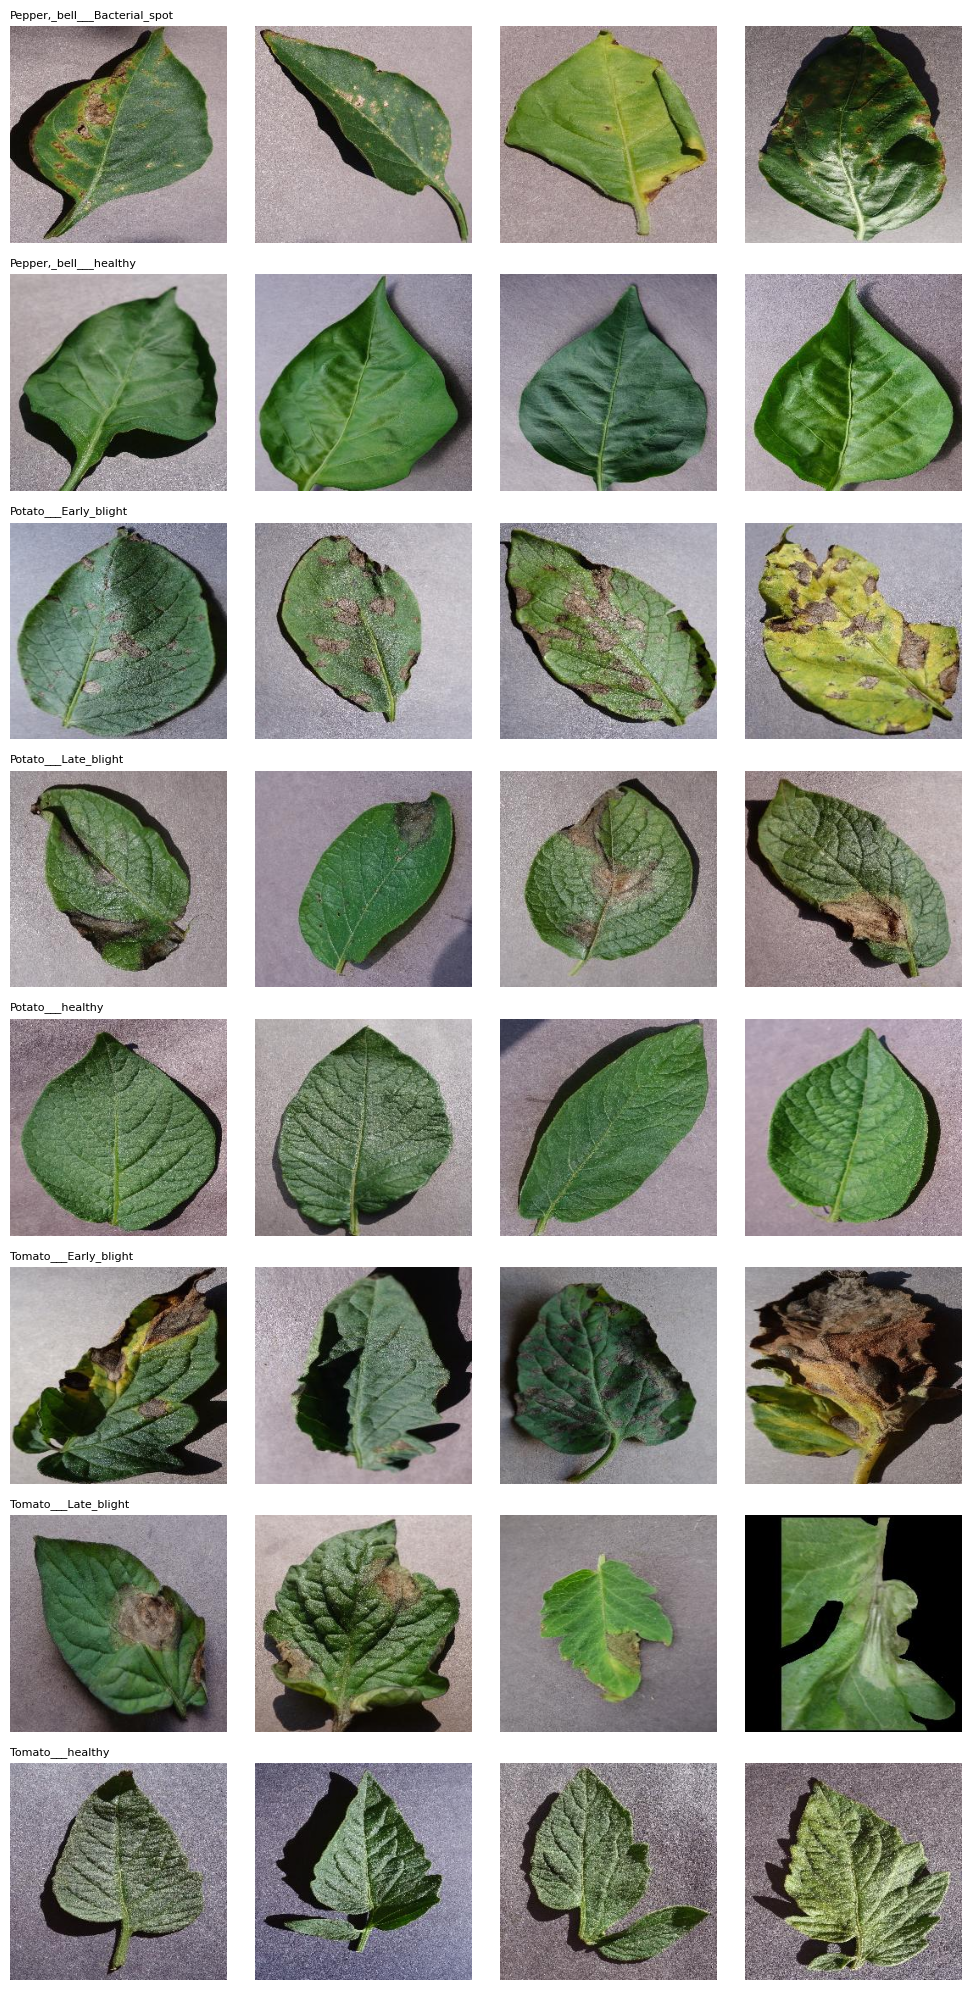

In [16]:
import random
import matplotlib.pyplot as plt
fig, axes = plt.subplots(8, 4, figsize=(10, 20))
for row, (name, path) in enumerate(sorted(selected.items())):
    files = random.sample([f for f in path.iterdir() if f.suffix.lower() in exts], 4)
    for col, f in enumerate(files):
        axes[row][col].imshow(Image.open(f))
        axes[row][col].axis("off")
        if col == 0:
            axes[row][col].set_title(name, fontsize=8, loc="left")
plt.tight_layout()
plt.show()

In [17]:
for name, path in sorted(selected.items()):
    c = Counter()
    for f in path.iterdir():
        if f.suffix.lower() in exts:
            src = f.name.split("___", 1)[-1]
            c[src.split(" ")[0]] += 1
    print(name, dict(c.most_common(6)))

Pepper,_bell___Bacterial_spot {'JR_B.Spot': 589, 'NREC_B.Spot': 408}
Pepper,_bell___healthy {'JR_HL': 1476, 'Screen': 1, 'bell-pepper-plant-61726.jpg': 1}
Potato___Early_blight {'RS_Early.B': 1000}
Potato___Late_blight {'RS_LB': 1000}
Potato___healthy {'RS_HL': 152}
Tomato___Early_blight {'RS_Erly.B': 1000}
Tomato___Late_blight {'RS_Late.B': 920, 'GHLB2': 744, 'GHLB_PS': 150, 'GHLB': 66, 'GHLB2ES': 27, 'GH_HL': 2}
Tomato___healthy {'RS_HL': 999, 'GH_HL': 590, 'CG1.JPG': 1, '2700323949_95aa2eaa01_o.jpg': 1}


6


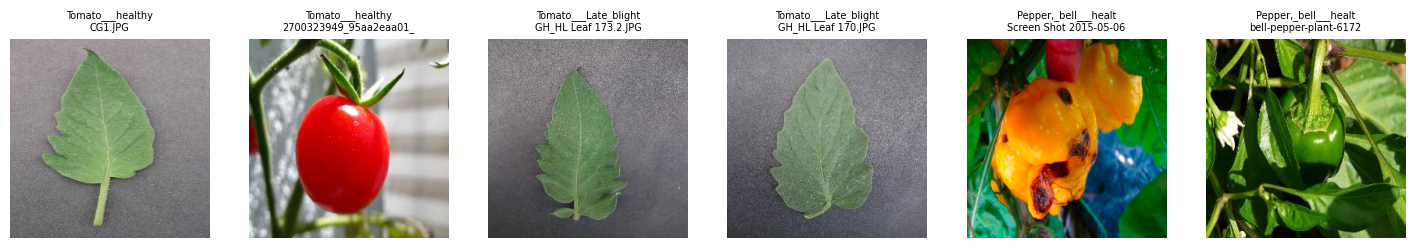

In [18]:
import matplotlib.pyplot as plt

odd = []
for name, path in selected.items():
    for f in path.iterdir():
        if f.suffix.lower() in exts:
            src = f.name.split("___", 1)[-1]
            late_gh = name == "Tomato___Late_blight" and src.startswith("GH_HL")
            web = src.startswith(("Screen", "bell-pepper", "CG1", "2700323949"))
            if late_gh or web:
                odd.append(f)

print(len(odd))
fig, axes = plt.subplots(1, len(odd), figsize=(3 * len(odd), 3))
for ax, f in zip(axes, odd):
    ax.imshow(Image.open(f))
    ax.axis("off")
    ax.set_title(f.parent.name[:20] + "\n" + f.name.split("___")[-1][:22], fontsize=7)
plt.show()

In [19]:
import re
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

root = Path("/content/data/plantvillage dataset/color")

# files to drop: the 6 odd files + all but one copy in each duplicate group
drop = set(odd)
for h, fs in dups.items():
    for f in sorted(fs)[1:]:
        drop.add(f)

def group_key(cls, fname):
    src = fname.split("___", 1)[-1]
    m = re.match(r"(GH_HL|GHLB\w*)\s+Leaf\s+(\d+)", src)
    if m:
        return f"{cls}|{m.group(1)}|{m.group(2)}"
    return fname  # no leaf id available: each image is its own group

rows = []
for cls, path in selected.items():
    for f in path.iterdir():
        if f.suffix.lower() in exts and f not in drop:
            rows.append({
                "path": str(f.relative_to(root)),
                "label": cls,
                "group": group_key(cls, f.name),
            })

df = pd.DataFrame(rows).reset_index(drop=True)
print(len(df), "images kept")

# 20 folds: 3 -> test (15%), 3 -> val (15%), 14 -> train (70%)
sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=42)
df["fold"] = -1
for i, (_, idx) in enumerate(sgkf.split(df, df["label"], df["group"])):
    df.loc[idx, "fold"] = i
df["split"] = df["fold"].map(lambda k: "test" if k < 3 else ("val" if k < 6 else "train"))

print(df.groupby(["label", "split"]).size().unstack())
df.to_csv("/content/drive/MyDrive/plant_manifest.csv", index=False)

9107 images kept
split                          test  train  val
label                                          
Pepper,_bell___Bacterial_spot   156    683  158
Pepper,_bell___healthy          217   1026  233
Potato___Early_blight           150    719  131
Potato___Late_blight            145    699  156
Potato___healthy                 23    106   23
Tomato___Early_blight           158    690  152
Tomato___Late_blight            271   1341  287
Tomato___healthy                232   1115  236


In [20]:
g = df.groupby("group")["split"].nunique()
print("groups appearing in more than one split:", (g > 1).sum())
print(df["split"].value_counts(normalize=True).round(3))

groups appearing in more than one split: 0
split
train    0.700
val      0.151
test     0.148
Name: proportion, dtype: float64


In [8]:
import json
import numpy as np
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight

print("TensorFlow", tf.__version__)   # write this down for Phase 7

df = pd.read_csv("/content/drive/MyDrive/plant_manifest.csv")
class_names = sorted(df["label"].unique())
label_to_idx = {c: i for i, c in enumerate(class_names)}
df["y"] = df["label"].map(label_to_idx)
json.dump(class_names, open("/content/drive/MyDrive/class_names.json", "w"))

train_y = df[df["split"] == "train"]["y"]
w = compute_class_weight("balanced", classes=np.arange(len(class_names)), y=train_y)
class_weight = dict(enumerate(w))
for i, c in enumerate(class_names):
    print(i, c, round(class_weight[i], 2))

TensorFlow 2.21.0
0 Pepper,_bell___Bacterial_spot 1.17
1 Pepper,_bell___healthy 0.78
2 Potato___Early_blight 1.11
3 Potato___Late_blight 1.14
4 Potato___healthy 7.52
5 Tomato___Early_blight 1.16
6 Tomato___Late_blight 0.59
7 Tomato___healthy 0.72


In [9]:
ROOT = "/content/data/plantvillage dataset/color/"
IMG, BATCH = 128, 32

augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomBrightness(0.1, value_range=(0, 255)),
])

def load(path, y):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG, IMG))
    return img, y

def make_ds(split, training):
    d = df[df["split"] == split]
    ds = tf.data.Dataset.from_tensor_slices(((ROOT + d["path"]).values, d["y"].values))
    if training:
        ds = ds.shuffle(len(d), seed=42)
    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.map(lambda x, y: (augment(x, training=True), y),
                    num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds("train", True)
val_ds = make_ds("val", False)
test_ds = make_ds("test", False)

x, y = next(iter(train_ds))
print(x.shape, x.dtype, float(tf.reduce_min(x)), float(tf.reduce_max(x)))

(32, 128, 128, 3) <dtype: 'float32'> 0.0 250.6084747314453


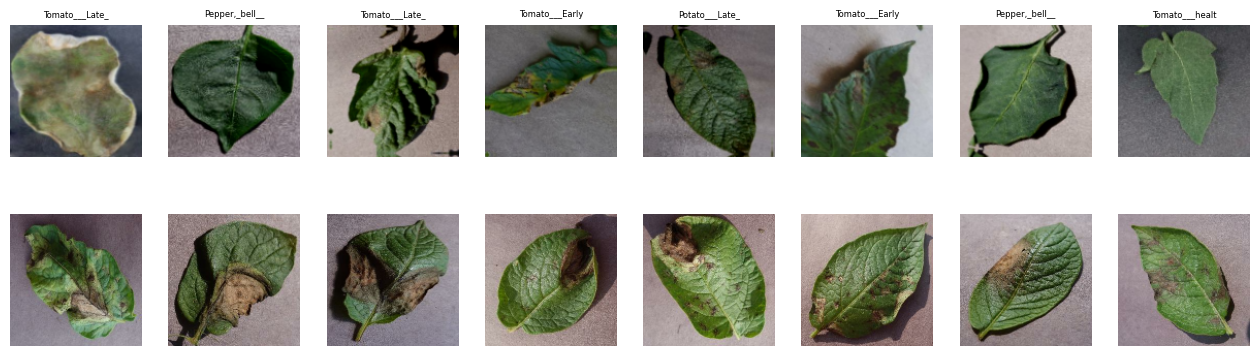

In [23]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for i in range(8):
    axes[0][i].imshow(x[i].numpy().astype("uint8")); axes[0][i].axis("off")
    axes[0][i].set_title(class_names[int(y[i])][:14], fontsize=6)
vx, vy = next(iter(val_ds))
for i in range(8):
    axes[1][i].imshow(vx[i].numpy().astype("uint8")); axes[1][i].axis("off")
axes[0][0].set_ylabel("train (augmented)")
plt.show()

In [10]:
from tensorflow.keras import layers, models

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return layers.MaxPooling2D()(x)

inputs = layers.Input((128, 128, 3))
x = layers.Rescaling(1 / 255)(inputs)
for f in (32, 64, 128, 256):
    x = conv_block(x, f)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)

model = models.Model(inputs, outputs, name="plant_cnn")
model.summary()

Model: "plant_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 32, 32, 128)    │             

 Total params: 1,209,064 (4.61 MB)

 Trainable params: 1,207,144 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [29]:
# Fetch a concrete batch of images and labels from the validation dataset
sample_x, sample_y = next(iter(val_ds))

# Predict using the model on the first 4 concrete images
p = model.predict(sample_x[:4], verbose=0)
print("Output shape:", p.shape)
print("Row sums (should be 1.0):", p.sum(axis=1).round(3))
print("First prediction probabilities:", p[0].round(3))

Output shape: (4, 8)
Row sums (should be 1.0): [1. 1. 1. 1.]
First prediction probabilities: [0.125 0.124 0.125 0.125 0.125 0.126 0.125 0.125]


In [1]:
import tensorflow as tf
print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))

2.21.0
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
import pandas as pd, os

manifest_path = "/content/drive/MyDrive/plant_manifest.csv"
print(os.path.exists(manifest_path), os.path.exists("/content/drive/MyDrive/class_names.json"))

m = pd.read_csv(manifest_path)
print(m.shape)
print(m.columns.tolist())
print(m.head(3))

True True
(9107, 5)
['path', 'label', 'group', 'fold', 'split']
                                                path                 label  \
0  Potato___Late_blight/304b3fa0-f0cb-41b5-b835-9...  Potato___Late_blight   
1  Potato___Late_blight/267d6db0-95db-4945-a6b0-b...  Potato___Late_blight   
2  Potato___Late_blight/d38d9e28-89a0-4650-8a2d-d...  Potato___Late_blight   

                                               group  fold  split  
0  304b3fa0-f0cb-41b5-b835-9bd13773150a___RS_LB 4...     2   test  
1  267d6db0-95db-4945-a6b0-bf05b11ef8ff___RS_LB 3...     1   test  
2  d38d9e28-89a0-4650-8a2d-dc5e6744b3b9___RS_LB 5...     9  train  


In [6]:
root = "/content/data/plantvillage dataset"
print(os.listdir(root))

p = m["path"].iloc[0]
for sub in [root, os.path.join(root, "color"), os.path.join(root, "PlantVillage")]:
    full = os.path.join(sub, p)
    print(os.path.exists(full), full[:90])

['grayscale', 'color', 'segmented']
False /content/data/plantvillage dataset/Potato___Late_blight/304b3fa0-f0cb-41b5-b835-9bd1377315
True /content/data/plantvillage dataset/color/Potato___Late_blight/304b3fa0-f0cb-41b5-b835-9bd1
False /content/data/plantvillage dataset/PlantVillage/Potato___Late_blight/304b3fa0-f0cb-41b5-b8


In [7]:
print(m["split"].value_counts())

split
train    6379
val      1376
test     1352
Name: count, dtype: int64


In [11]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks = [
    EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    ModelCheckpoint("/content/drive/MyDrive/plant_cnn_best.keras",
                    monitor="val_loss", save_best_only=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    class_weight=class_weight,
    callbacks=callbacks,
)

Epoch 1/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 92s 321ms/step - accuracy: 0.5930 - loss: 1.1255 - val_accuracy: 0.2609 - val_loss: 4.3133 - learning_rate: 0.0010
Epoch 2/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 41s 205ms/step - accuracy: 0.7404 - loss: 0.7052 - val_accuracy: 0.3001 - val_loss: 5.3948 - learning_rate: 0.0010
Epoch 3/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 43s 214ms/step - accuracy: 0.8036 - loss: 0.5437 - val_accuracy: 0.5102 - val_loss: 2.2367 - learning_rate: 0.0010
Epoch 4/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 43s 213ms/step - accuracy: 0.8453 - loss: 0.4336 - val_accuracy: 0.6926 - val_loss: 1.4040 - learning_rate: 0.0010
Epoch 5/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 41s 206ms/step - accuracy: 0.8620 - loss: 0.3824 - val_accuracy: 0.5233 - val_loss: 2.3603 - learning_rate: 0.0010
Epoch 6/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 41s 205ms/step - accuracy: 0.8755 - loss: 0.3445 - val_accuracy: 0.2660 - val_loss: 3.8566 - learning_rate: 0.0010
Epoch 7/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 40s 202ms/step - accuracy: 0.9

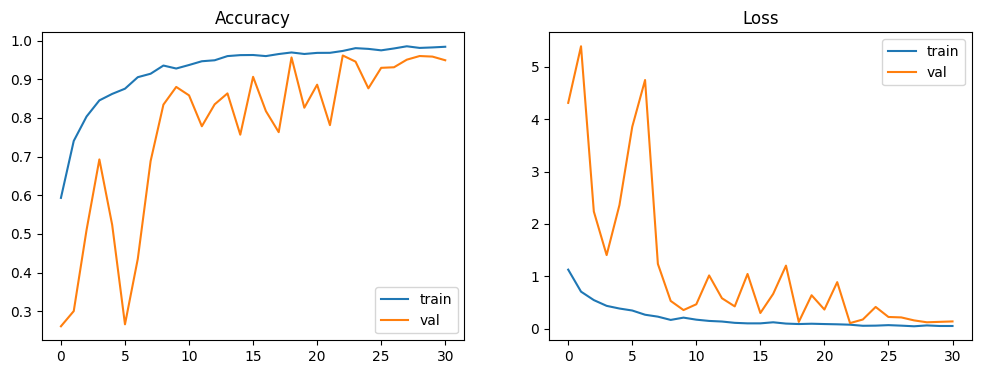

In [12]:
import json
import matplotlib.pyplot as plt

json.dump(history.history, open("/content/drive/MyDrive/history.json", "w"))
h = history.history

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["accuracy"], label="train"); ax[0].plot(h["val_accuracy"], label="val")
ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(h["loss"], label="train"); ax[1].plot(h["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].legend()
plt.show()

In [13]:
print("model" in globals(), "test_ds" in globals(), "test_df" in globals() or "df" in globals())
print(len(df[df["split"] == "test"]))

True True True
1352


In [14]:
import numpy as np

test = df[df["split"] == "test"].reset_index(drop=True)
y_true = test["y"].to_numpy()

probs = model.predict(test_ds, verbose=0)
y_pred = probs.argmax(axis=1)

print(probs.shape, len(y_true))
print("Test accuracy:", round((y_pred == y_true).mean(), 4))

(1352, 8) 1352
Test accuracy: 0.9697


In [15]:
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

                               precision    recall  f1-score   support

Pepper,_bell___Bacterial_spot      0.981     0.994     0.987       156
       Pepper,_bell___healthy      0.991     0.986     0.988       217
        Potato___Early_blight      0.987     1.000     0.993       150
         Potato___Late_blight      0.927     0.966     0.946       145
             Potato___healthy      0.793     1.000     0.885        23
        Tomato___Early_blight      0.946     0.994     0.969       158
         Tomato___Late_blight      1.000     0.886     0.939       271
             Tomato___healthy      0.967     1.000     0.983       232

                     accuracy                          0.970      1352
                    macro avg      0.949     0.978     0.961      1352
                 weighted avg      0.971     0.970     0.970      1352



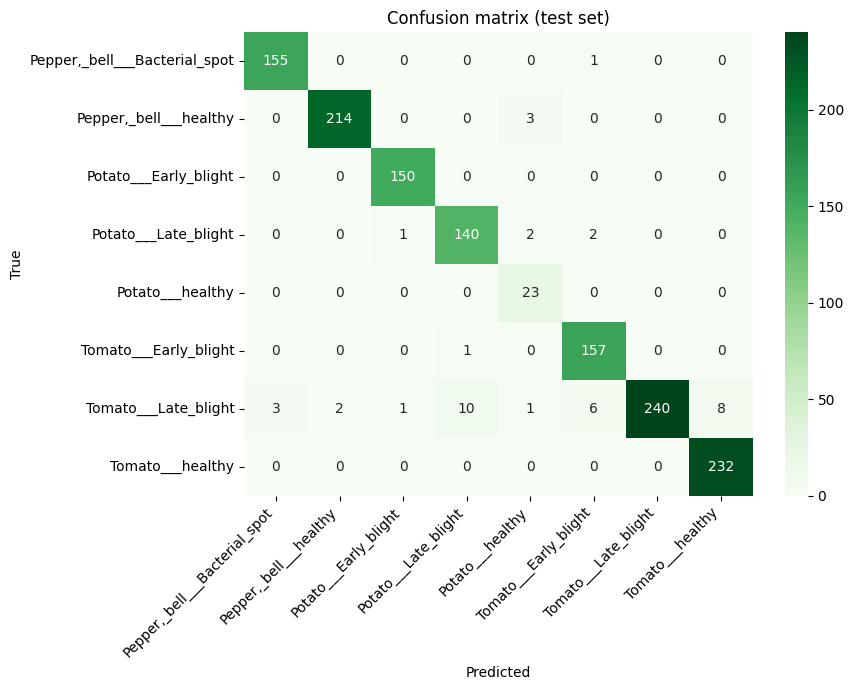

In [16]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title("Confusion matrix (test set)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/confusion_matrix.png", dpi=150)
plt.show()

In [17]:
test = df[df["split"] == "test"].reset_index(drop=True)
test["pred"] = y_pred
test["correct"] = test["pred"] == test["y"]
test["source"] = test["path"].apply(lambda p: "GH" if "GH_" in p else "other")

print(test.groupby("source")["correct"].agg(["mean", "count"]))
print(test.groupby(["label", "source"])["correct"].agg(["mean", "count"]))

           mean  count
source                
GH      1.00000     92
other   0.96746   1260
                                          mean  count
label                         source                 
Pepper,_bell___Bacterial_spot other   0.993590    156
Pepper,_bell___healthy        other   0.986175    217
Potato___Early_blight         other   1.000000    150
Potato___Late_blight          other   0.965517    145
Potato___healthy              other   1.000000     23
Tomato___Early_blight         other   0.993671    158
Tomato___Late_blight          other   0.885609    271
Tomato___healthy              GH      1.000000     92
                              other   1.000000    140


In [18]:
import json
from sklearn.metrics import classification_report

report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
json.dump(report, open("/content/drive/MyDrive/test_report.json", "w"), indent=2)

test["pred_label"] = [class_names[i] for i in y_pred]
test["confidence"] = probs.max(axis=1)
test.to_csv("/content/drive/MyDrive/test_predictions.csv", index=False)

print("Saved:", "test_report.json", "test_predictions.csv")

Saved: test_report.json test_predictions.csv
